# Ejercicio 1: Una imagen como matriz y como vector

## Inciso a)

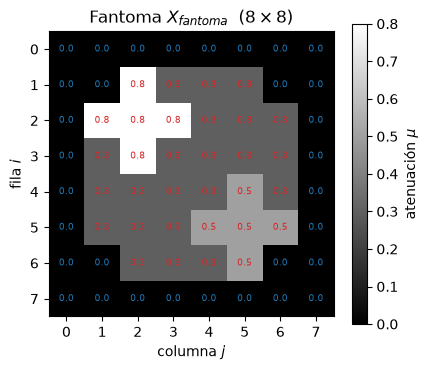

In [6]:
import numpy as np
import matplotlib.pyplot as plt

X_fantoma = np.array([
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
    [0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
    [0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
    [0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

n = 8   # la imagen es de n x n píxeles

fig, ax = plt.subplots(figsize=(4.6, 3.9))
im = ax.imshow(X_fantoma, cmap="gray", vmin=0.0, vmax=X_fantoma.max())
ax.set_title(r"Fantoma $X_{fantoma}$  ($8 \times 8$)")
ax.set_xlabel("columna $j$")
ax.set_ylabel("fila $i$")
ax.set_xticks(range(n))
ax.set_yticks(range(n))
for i in range(n):
    for j in range(n):
        v = X_fantoma[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                color="tab:red" if v > 0 else "tab:blue")
fig.colorbar(im, ax=ax, label=r"atenuación $\mu$")
plt.show()


## Inciso b)

In [7]:
# Esto pasa de ser una matriz de 8x8 a un vector de 64 elementos
x_fantoma = X_fantoma.reshape(-1)
    # El (-1) le dice a numpy que calcule la dimension solo

# Verificar las dimensiones luego del reshape
print("x_fantoma:", x_fantoma.shape)

x_fantoma: (64,)


## Inciso c)


In [8]:
# Para devolverla asu estado original le decimos que haga un reshape de nuevo a una 8x8
X_fantoma_original = x_fantoma.reshape(8, 8)

# Chequeao
print("Es la misma?", np.array_equal(X_fantoma_original, X_fantoma))
print("allclose: ", np.allclose(X_fantoma_original, X_fantoma))

Es la misma? True
allclose:  True


## Inciso d)

$x_k$ es la **atenuación del píxel $k$**, o sea cuánto frena ese material a los rayos X que lo atraviesan.

Según su valor:
- **Alto**: hay un material que "tapa" mucho, entonces al detector le llega poca intensidad. En la imagen se ve clarito.
- **Bajo**: hay un material más transparente, el rayo lo atraviesa perdiendo poca intensidad. Se vería gris oscuro.
- **Nulo**: no hay material, el rayo pasa sin atenuarse y el píxel no aporta a ninguna medición. Se ve negro.

Para verificar se puede ver el gráfico del inciso a) del mismo punto.

Cada detector del otro lado registra una medición que, tras el cambio de variable logarítmico, es la suma de las atenuaciones de los píxeles que el rayo atravesó, cada una pesada por cuánto la atravesó.

## Inciso e)

In [9]:
i0, j0 = 3, 5   # pixel elegido

X_modificada = X_fantoma.copy()
X_modificada[i0, j0] = 1.0
x_modificado = X_modificada.reshape(-1)

cambiadas = np.flatnonzero(x_modificado != x_fantoma)
print(f"Modificamos X[3, 5]: {X_fantoma[3, 5]} -> {X_modificada[3, 5]}")
print("componentes de x que cambiaron:", cambiadas)
print("k predicho por la fórmula k = i*n + j:", i0 * n + j0)

Modificamos X[3, 5]: 0.3 -> 1.0
componentes de x que cambiaron: [29]
k predicho por la fórmula k = i*n + j: 29


Esa cuenta es la fórmula:


k = (cuántas filas salteo) * (ancho de la fila) + (cuánto avanzo en la fila)

$k = i * n + j$

Siendo $k$ el índice de posiciones de x_modificado